<h1>Практическая работа: "Знакомство с алгоритма k-ближайших соседей (kNN)"</h1>

__K-ближайший сосед с использованием scikit-learn__

__Задача обучения__  
Набор данных "Ирисы Фишера". Нужно определить к какому классу принадлежит неопознанное растение ириса,
Классификация осуществляется на основе размеров чашелистиков и лепестков.

In [138]:
#Импорт необходимых библиотек
import warnings

warnings.filterwarnings('ignore')

In [139]:
!pip install mlxtend


[notice] A new release of pip is available: 25.0.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [140]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import itertools
from mlxtend.plotting import plot_decision_regions

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

%matplotlib inline
plt.rcParams["figure.figsize"] = (10,5)

__Изучение набора данных__  
Набор данных "Ирисы Фишера" — это популярный многомерный набор данных, часто используемый в машинном обучении. 
Набор данных состоит из 150 образцов, равномерно распределенных по трем видам ирисов: 
ирис сетозный, ирис виргинский, ирис разноцветный. 
Каждый образец состоит из четырех атрибутов: длины и ширины чашелистиков и лепестков в сантиметрах.
Задача состоит в том, чтобы предсказать, к какому классу принадлежит неопознанное растение ириса,
основываясь на размерах чашелистиков и лепестков.

In [141]:
dataset = datasets.load_iris()
df = pd.DataFrame(data=np.c_[dataset['data'], dataset['target']],
                    columns=dataset['feature_names'] + ['target'])

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0


__Описания наборов данных__

In [142]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    float64
dtypes: float64(5)
memory usage: 6.0 KB


In [143]:
dict(zip( dataset.target_names, df['target'].unique()))

{np.str_('setosa'): np.float64(0.0),
 np.str_('versicolor'): np.float64(1.0),
 np.str_('virginica'): np.float64(2.0)}

In [144]:
temp_df = df.copy()

temp_df['target'] = temp_df['target'].map(dict(zip( temp_df['target'].unique(), dataset.target_names)))

<Axes: xlabel='target', ylabel='count'>

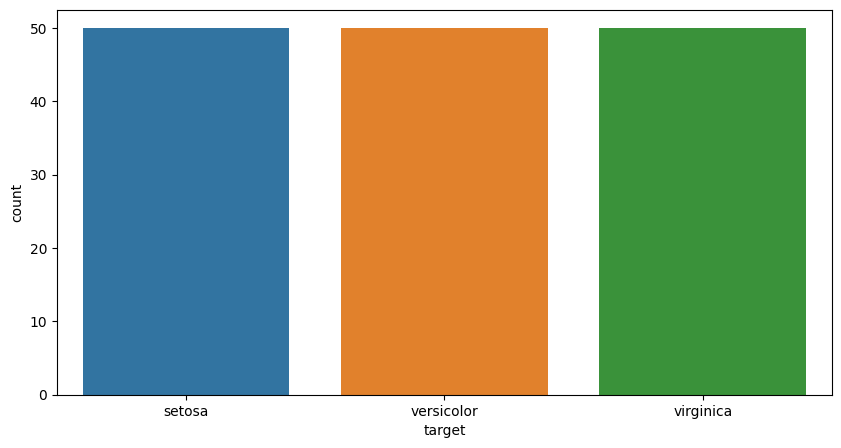

In [145]:
sns.countplot(x='target', hue='target', data=temp_df)

Из графика выше мы видим, что наши данные идеально сбалансированы.

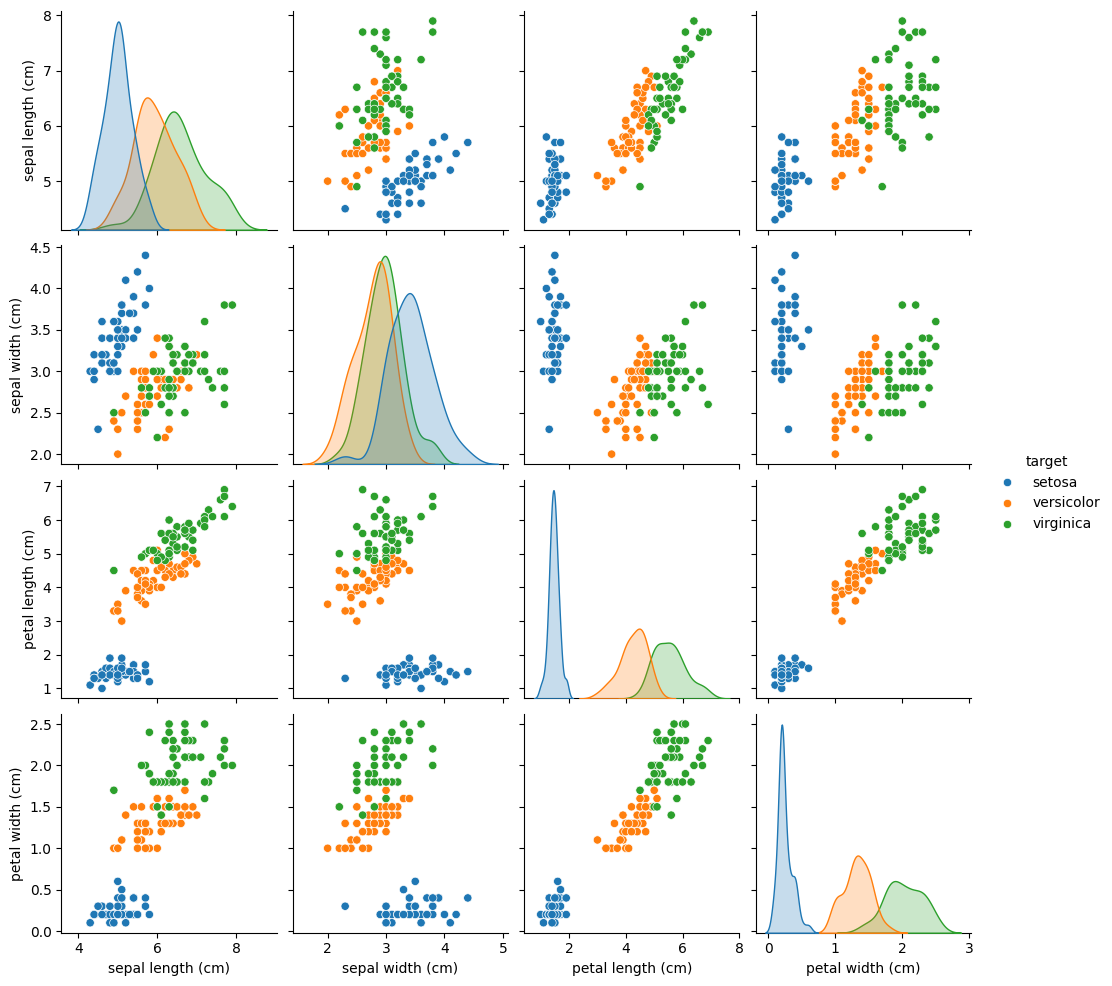

In [146]:
sns.pairplot(temp_df, hue='target')

На графике выше мы можем видеть взаимосвязь между каждой функцией. Мы можем увидеть, являются ли признаки разделимыми или нет.

<h2>Синтетический набор данных KNN</h2>

In [147]:
from IPython.display import display, Javascript, HTML
from IPython.display import IFrame
display(HTML('build.html'))

<h2>Модели КNN</h2>

Теперь мы построим разные модели для разных пар признаков, чтобы увидеть, насколько полезны признаки для определения их вида.

In [148]:
# Helper functions

def display_confusion_matrix(
    matrix, labels=None,
    title="Confusion Matrix",
    xlabel="Predicted",
    ylabel="Actual",
    figsize=None,
    cmap="Blues",
    vmin=None,
    vmax=None,
):
    """Display a confusion matrix. 
  
    Display the confusion matrix found in matrix using matplotlib.
  
    Parameters
    ----------
    matrix : array-like
        Confusion matrix to display, shape [n_classes, n_classes].
    
    labels : array-like, default=None
        Class labels for the confusion matrix, shape [n_classes].
        
    title : str, default='Confusion Matrix'
        Title displayed on the confusion matrix.
    
    xlabel : str, default='Predicted'
        x-label displayed on the confusion matrix.
    
    ylabel : str, default='Actual'
        y-label displayed on the confusion matrix.
    
    figsize : array-like
        Array-like, length two, specifying the figsize of the plot.
        
    cmap : matplotib.colors.Colormap or str, default='Blues'
        Colormap used when displaying the entries of the confusion matrix.
        
    vmin,vmax : int or float
        *vmin* and *vmax* define the data range that the colormap covers.
    """
    
    if labels is None:
        labels = [""]*len(matrix)
    if vmin is None:
        vmin = 0.
    if vmax is None:
        vmax = np.sum(matrix[0])
    t_hold = (vmax-vmin) / 2.
    fig,ax = plt.subplots(figsize=figsize)
    ax.imshow(matrix, cmap=cmap)
    for row,col in itertools.product(range(len(labels)), range(len(labels))):
        color = "white" if matrix[row,col] > t_hold else "black"
        ax.text(col, row, matrix[row, col], horizontalalignment="center", color=color)
    tick_marks = np.arange(len(labels))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=40, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_yticks(np.arange(len(labels)))
    ax.set_yticklabels(labels)
    plt.show()

<h2>Модель 1 (длина чашелистика и ширина чашелистика)</h2>  
Для начала мы собираемся построить модель KNN с длиной и шириной чашелистика. Мы обучим модель этим двум функциям и оценим ее эффективность с помощью карты классификации и матрицы путаницы.

In [149]:
X = df[['sepal length (cm)', 'sepal width (cm)']]
y_true = df['target']
model_1 = KNeighborsClassifier()
model_1.fit(X, y_true)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


<h3>Оценка модели 1</h3>

In [150]:
# plot_decision_regions(X.values, y_true.values.astype(np.integer), model_1)

[[49  1  0]
 [ 0 38 12]
 [ 0 12 38]]


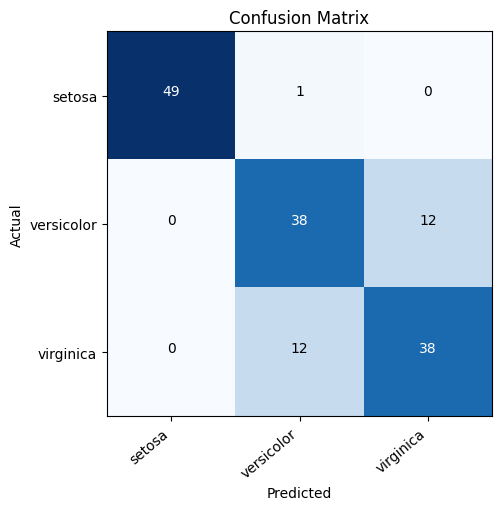

In [151]:
y_hat = model_1.predict(X)
labels = df["target"].unique()

matrix = confusion_matrix(y_true, y_hat, labels=labels, normalize=None)
print(matrix)

display_confusion_matrix(matrix, dataset.target_names)

<h1>Модель 2 (длина и ширина лепестка)</h1>  
Теперь для нашей второй модели мы собираемся использовать функции длины и ширины лепестка в качестве входных данных.

In [152]:
X = df[['petal length (cm)', 'petal width (cm)']]

model_2 = KNeighborsClassifier()
model_2.fit(X, y_true)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


__Model 2 Evaluation__

In [153]:
# plot_decision_regions(X.values, y_true.values.astype(np.integer), model_2)

[[50  0  0]
 [ 0 47  3]
 [ 0  3 47]]


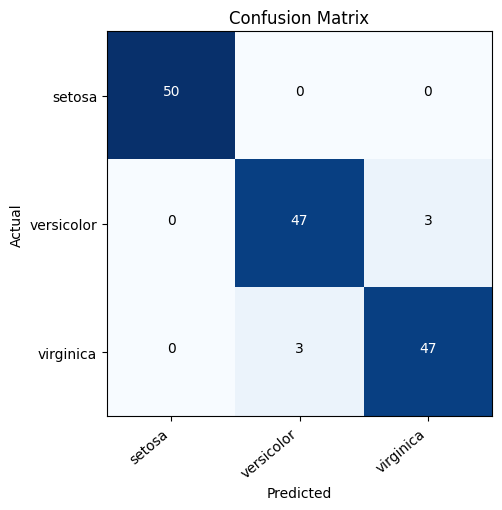

In [154]:
y_hat = model_2.predict(X)

matrix = confusion_matrix(y_true, y_hat, labels=labels, normalize=None)
print(matrix)

display_confusion_matrix(matrix, dataset.target_names)

<h1>Модель 3 (все функции)</h1>  
Теперь что касается нашей окончательной модели, мы собираемся использовать все доступные функции и обучить нашу модель KNN.

In [155]:
X = df.drop(['target'], axis=1)

In [156]:
model_3 = KNeighborsClassifier()
model_3.fit(X, y_true)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


__Модель 3 Оценка__

[[50  0  0]
 [ 0 47  3]
 [ 0  2 48]]


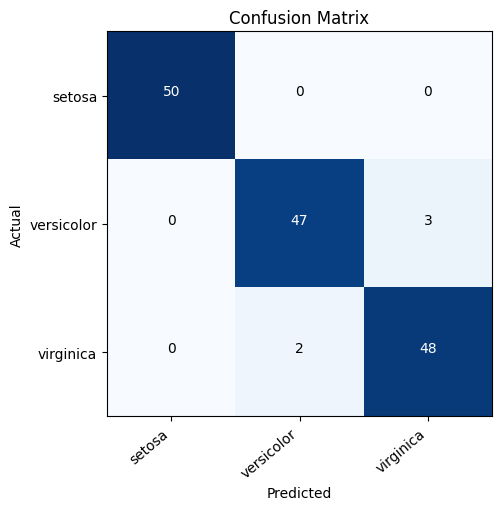

In [157]:
y_hat = model_3.predict(X)

matrix = confusion_matrix(y_true, y_hat, labels=labels, normalize=None)
print(matrix)

display_confusion_matrix(matrix, dataset.target_names)

Вы можете видеть, что окончательная модель со всеми функциями работает лучше, чем все другие модели. Меньше ошибочной классификации.

Однако до сих пор мы обучали и оценивали наши модели в одном и том же наборе данных. Использование одних и тех же данных для обучения и оценки не рекомендуется.

__Модель на разделенном наборе данных__

Здесь мы разделим наш набор данных на обучающий и тестовый набор и обучим нашу модель в обучающем наборе. Позже во время оценки мы собираемся использовать наш изолированный набор тестов.

In [158]:
X = df.drop(['target'], axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3)

In [159]:
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [160]:
preds = knn.predict(X_test)

print(classification_report(preds, y_test))

              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00        15
         1.0       0.93      1.00      0.97        14
         2.0       1.00      0.94      0.97        16

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



[[15  0  0]
 [ 0 14  1]
 [ 0  0 15]]


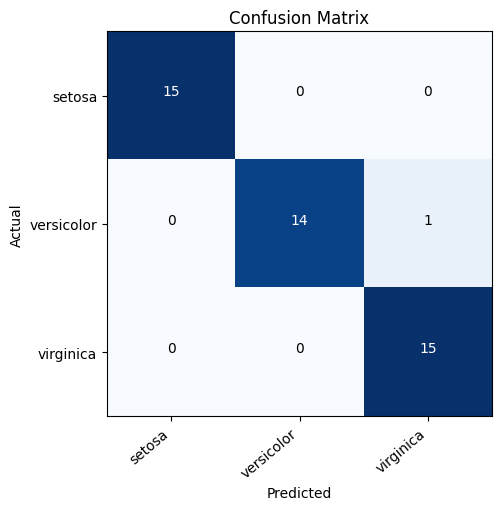

In [161]:
matrix = confusion_matrix(y_test, preds, labels=y.unique(), normalize=None)
print(matrix)

display_confusion_matrix(matrix, dataset.target_names)

Выше вы можете видеть, что точность нашего набора тестовых данных составляет 98%.

Из матрицы путаницы мы также видим, что у нас очень низкий уровень ошибок классификации.

Для наших вышеупомянутых моделей мы также можем использовать данные обучения и тестирования отдельно, оценивать эти модели, а затем выбирать лучшую модель.

<h1>Задание</h1>  
С помощью метода kNN определить качество красного вина. Использовать датасет winequality-red.csv, который находится в папке data.
Для этого разделить набор данных на обучающий и тестовый набор и обучим нашу модель в обучающем наборе. 
Построить матрицу путаници. Сделать выводы по полученным результатам. 

In [162]:
from math import ceil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from numpy.typing import NDArray
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.linear_model import LogisticRegression

In [175]:
def evaluate_classification_models(
    predictions: dict[str, NDArray[np.float64]], y: NDArray[np.float64]
) -> pd.DataFrame:
    """Evaluate multiple classification model predictions on the provided dataset.

    Args:
        predictions (dict[str, NDArray[np.float64]]): Dictionary mapping model names
            to predicted target arrays for the dataset.
        y (NDArray[np.float64]): True binary target values of shape (n_samples,).

    Returns:
        pd.DataFrame: DataFrame containing classification metrics — Accuracy, Precision,
            Recall, F1-score, and ROC AUC — for each model. Columns correspond to
            model names, rows correspond to the metric names.
    """
    evaluations = pd.DataFrame(
        columns=predictions.keys(),
        index=["Accuracy", "Precision", "Recall", "F1-score"],
    )

    for name, y_pred in predictions.items():
        accuracy = accuracy_score(y, y_pred)
        precision = precision_score(y, y_pred)
        recall = recall_score(y, y_pred)
        f1 = f1_score(y, y_pred)

        evaluations.loc[:, name] = [accuracy, precision, recall, f1]

    return evaluations.astype(float)

In [176]:
def plot_confusion_matrices(
    predictions: dict[str, NDArray[np.int64]],
    y_true: NDArray[np.int64],
    n_cols: int = 2,
) -> None:
    """Plot confusion matrices for multiple classification models.

    Each confusion matrix compares the true labels to predictions from one model.
    The plots are arranged in a grid layout for easy comparison.

    Args:
        predictions (dict[str, NDArray[np.int64]]): A dictionary mapping model names to
            their predicted labels (1D array of shape (n_samples,)).
        y_true (NDArray[np.int64]): True class labels (1D array of shape (n_samples,)).
        n_cols (int, optional): Number of columns in the subplot grid layout.
            Default is 2.
    """
    n_models = len(predictions)
    n_cols = min(n_models, n_cols)
    n_rows = ceil(n_models / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
    axes = np.array(axes).reshape(-1)

    for ax, (name, y_pred) in zip(axes, predictions.items(), strict=False):
        conf_matrix = confusion_matrix(y_true, y_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
        ax.set_xlabel("Predicted Labels")
        ax.set_ylabel("True Labels")
        ax.set_title(name)

    for i in range(n_models, len(axes)):
        fig.delaxes(axes[i])

    plt.tight_layout()
    plt.show() 

In [177]:
df = pd.read_csv("winequality-red.csv")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [178]:
df["status"] = (df["quality"] >= 7).astype(int)

features = [
    'fixed acidity', 
    'volatile acidity', 
    'citric acid', 
    'residual sugar',
    'chlorides', 
    'free sulfur dioxide', 
    'total sulfur dioxide', 
    'density',
    'pH', 
    'sulphates', 
    'alcohol'
]

X, y = df[features], df["status"]
X, y = X.to_numpy(), y.to_numpy()

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [179]:
class MyKNeighborsClassifier:
    """K-Nearest Neighbors Classifier with Gaussian kernel weighting.

    Predicts the class label for each input sample based on the weighted vote
    of its k nearest neighbors in the training data, using Minkowski distance
    and a Gaussian kernel to assign weights to neighbors.

    Attributes:
        k_neighbors (int): Number of nearest neighbors to consider.
        p (float): Power parameter for the Minkowski distance.
        h (float): Bandwidth parameter for the Gaussian kernel.
        X_train (NDArray[np.float64] | None): Training features.
        y_train (NDArray[np.float64] | None): Training labels.
    """

    def __init__(self, k_neighbors: int = 3, p: float = 2.0, h: float = 1.0) -> None:
        """Initialize the KNN classifier.

        Args:
            k_neighbors (int, optional): Number of neighbors to consider. Defaults to 3.
            p (float, optional): Order of the Minkowski distance metric.
                Defaults to 2.0.
            h (float, optional): Bandwidth parameter for the Gaussian kernel.
                Defaults to 1.0.
        """
        self.k_neighbors = k_neighbors
        self.p = p
        self.h = h

        self.X_train: NDArray[np.float64] | None = None
        self.y_train: NDArray[np.int64] | None = None

    def _gaussian_kernel(self, t: NDArray[np.float64]) -> NDArray[np.float64]:
        """Gaussian (normal) kernel function.

        Args:
            t (NDArray[np.float64]): Input values.

        Returns:
            NDArray[np.float64]: Kernel-weighted values.
        """
        return np.exp(-(t**2) / 2) / np.sqrt(2 * np.pi)

    def _get_distances(self, x: float) -> NDArray[np.float64]:
        """Compute Minkowski distances from a single sample to all training samples.

        Args:
            x (float): Single sample.

        Returns:
            NDArray: Distances from x to each sample in X_train.
        """
        return np.sum(np.abs(self.X_train - x) ** self.p, axis=1) ** (1 / self.p)

    def fit(self, X: NDArray[np.float64], y: NDArray[np.int64]) -> None:
        """Store training data for future predictions.

        Args:
            X (NDArray[np.float64]): Training feature matrix of shape
                (n_samples, n_features).
            y (NDArray[np.int64]): Target values of shape (n_samples,).
        """
        self.X_train = X
        self.y_train = y

    def predict(self, X: NDArray[np.float64]) -> NDArray[np.int64]:
        """Predict class labels for input samples.

        Args:
            X (NDArray[np.float64]): Input samples of shape (n_samples, n_features).

        Returns:
            NDArray[np.int64]: Predicted class labels.
        """
        y_pred = []
        for x_new in X:
            distances = self._get_distances(x_new)

            neighbors_idx = distances.argsort()[: self.k_neighbors]
            neighbor_labels = self.y_train[neighbors_idx].astype(np.float64)
            neighbor_distances = distances[neighbors_idx]

            weights = self._gaussian_kernel(neighbor_distances / self.h)

            class_weights = {}
            for label, weight in zip(neighbor_labels, weights, strict=False):
                class_weights[label] = class_weights.get(label, 0) + weight

            predicted_label = max(class_weights, key=class_weights.get)
            y_pred.append(predicted_label)

        return np.array(y_pred, dtype=np.int64)

In [192]:
my_model = MyKNeighborsClassifier(k_neighbors=3, p=3, h=5.8)
my_model.fit(X_train, y_train)

log_model = LogisticRegression(penalty="l2", solver="liblinear", max_iter=1000, class_weight="balanced", random_state=42)
log_model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'liblinear'
,max_iter,1000
,multi_class,'deprecated'


In [193]:
preds = {
    "kNN": my_model.predict(X_val),
    "LogisticRegression": log_model.predict(X_val),
}

In [194]:
evaluate_classification_models(preds, y_val)

,kNN,LogisticRegression
Accuracy,0.840625,0.806250
Precision,0.388889,0.385542
Recall,0.325581,0.744186
F1-score,0.354430,0.507937


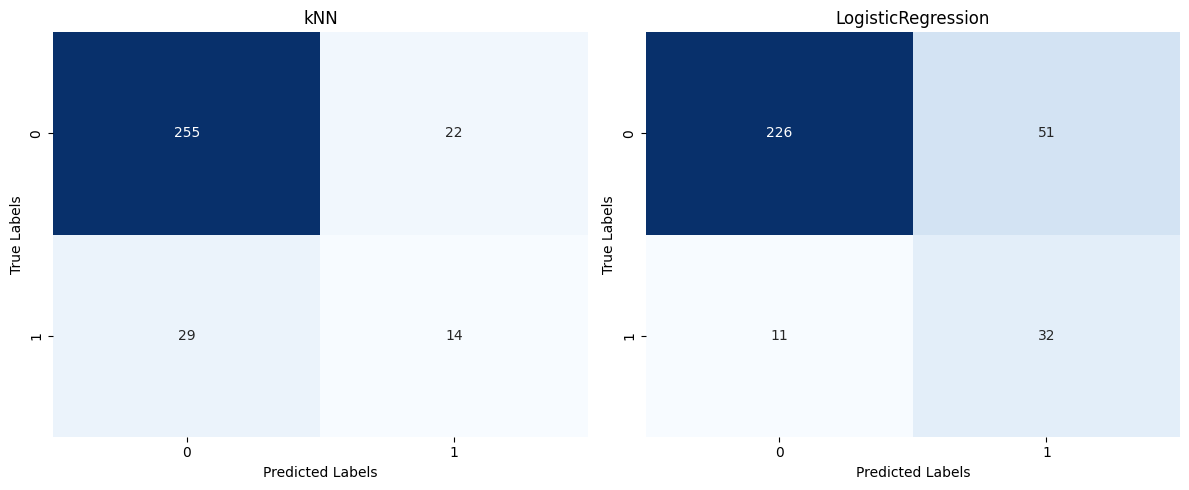

In [ ]:
plot_confusion_matrices(preds, y_val)

### Вывод

kNN показал более высокую точность и precision, но почти не находит хорошие вина из-за низкого recall. Логистическая регрессия лучше улавливает положительный класс, имеет более высокий F1-score и ROC AUC, поэтому она надёжнее для классификации качества вина.